# Figure 7 — HMDA mapping: Single-Prompt vs Multi-Step (E2)

Style and heatmap code copied verbatim from `3_mapper_analysis_simpler.ipynb`; data from `results/<HMDA_RESULTS>/e2_mapping/`.

In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib as mpl
from IPython.display import display, Markdown

# ── Publication style ──────────────────────────────────────────────────────────
mpl.rcParams.update({
    "font.family":       "serif",
    "font.size":         10,
    "axes.titlesize":    10,
    "axes.labelsize":    9,
    "xtick.labelsize":   9,
    "ytick.labelsize":   9,
    "legend.fontsize":   9,
    "figure.dpi":        300,
    "savefig.dpi":       300,
    "savefig.bbox":      "tight",
    "text.usetex":       False,   # set True if LaTeX is available
    "axes.linewidth":    0.6,
    "xtick.major.width": 0.6,
    "ytick.major.width": 0.6,
})


# Notebook-ready script
# ---------------------
# Reads a CSV with model-selection results and generates two LaTeX booktabs tables:
#   1) LLM mapper
#   2) MultiStep mapper
#
# Layout: datasets as row groups, metrics as columns.
# Rows = models, Groups = datasets, Columns = 3 metrics.

from pathlib import Path
import pandas as pd
import numpy as np
from IPython.display import display, Markdown
import matplotlib.colors as mcolors

# ============================================================
# 1) CONFIGURATION YOU MAY WANT TO EDIT
# ============================================================

CSV_PATH = "results_summary_all.csv"   # change if needed
ONLY_SUCCESS = True
DECIMALS = 2

# Metrics to show in the table.
# "kind" controls how the column is rendered:
#   - "single": one numeric column
#   - "mean_std": render as "mean ± std", ranked by the mean
METRICS = [
    {
        "key": "constraint_exact_f1",
        "label": "Constraint\nExact F1",
        "kind": "single",
    },
    {
        "key": "pairwise_viol_f1",
        "label": "Pairwise Viol.\nF1",
        "kind": "mean_std",
        "mean_col": "pairwise_viol_f1_mean",
        "std_col": "pairwise_viol_f1_std",
    },
    {
        "key": "agg_viol_f1",
        "label": "Aggregate\nViol. F1",
        "kind": "single",
    },
]

# Order of implementations in output
IMPLEMENTATION_ORDER = ["llm", "multi_step_refinement"]

# Order of datasets in output; any dataset not listed here will be appended alphabetically
DATASET_ORDER = [
    "hospital",
    "restaurant",
    "sisu",
    "tax",
]

# Order of models in output; any model not listed here will be appended alphabetically
MODEL_ORDER = [
    "mistral-small-2506",
    "mistral-large-2512",
    "gpt-5-mini",
    "gpt-5",
    "llama-3.3-70b-versatile",
]

# Pretty names used in the table rows
MODEL_DISPLAY = {
    "mistral-small-2506":      "Mistral-Small",
    "mistral-large-2512":      "Mistral-Large",
    "llama-3.3-70b-versatile": "Llama 3.3",
    "gpt-5-mini":              "GPT-5 mini",
    "gpt-5":                   "GPT-5",
}

# Pretty dataset names used in row-group headers
DATASET_DISPLAY = {
    "tax":        "Tax",
    "hospital":   "Hospital",
    "restaurant": "Restaurant",
    "sisu":       "SISU",
}

# Pretty implementation names used in captions / labels / headings
IMPLEMENTATION_DISPLAY = {
    "llm": "Single-Prompt",
    "multi_step_refinement": "Multi-Step",
}

# Optional: if you want to override row grouping by implementation based on variant_name
IMPLEMENTATION_VARIANT_HINTS = {
    "LLM": "llm",
    "Multi-Step": "multi_step_refinement",
}

# LaTeX labels
LABELS = {
    "llm": "tab:model-selection-llm",
    "multi_step_refinement": "tab:model-selection-multistep",
}




In [2]:
# HMDA results: reads ONLY small result files under results/<HMDA_RESULTS>/ (never data CSVs).
# Environment: HMDA_RESULTS (default "hmda"; e.g. "hmda_v2"), HMDA_MODELS (model manifest).
import os
from pathlib import Path
import pandas as pd
import yaml

ROOT = Path.cwd()
while not (ROOT / "experiments").is_dir():
    ROOT = ROOT.parent
RESULTS_DIR = ROOT / "results" / os.environ.get("HMDA_RESULTS", "hmda")
FIG_DIR = RESULTS_DIR / "figures"
import sys
sys.path.insert(0, str(ROOT / "notebooks" / "results_analysis"))
FIG_DIR.mkdir(parents=True, exist_ok=True)
MANIFEST = yaml.safe_load(
    (ROOT / os.environ.get("HMDA_MODELS", "experiments/configs/hmda_models.yaml")).read_text()
)

# Dataset group (defaults: HMDA). Paper datasets: RESULTS_DATASETS=hospital,restaurant,sisu,tax
HMDA_DATASET_ORDER = os.environ.get("RESULTS_DATASETS", "hmdaz,hmda_checks").split(",")
HMDA_DATASET_LABELS = {
    "hmdaz": "HMDAZ", "hmda_checks": "HMDA Checks", "hospital": "Hospital",
    "restaurant": "Restaurant", "sisu": "SISU", "tax": "Tax",
}
GROUP_LABEL = os.environ.get("RESULTS_LABEL", "HMDA")
ROW_NOTE = os.environ.get("ROW_NOTE", "first 1,000,000 rows per dataset")
FIG_PREFIX = os.environ.get("FIG_PREFIX", "hmda")
# Model order/labels follow the manifest (paper_name)
HMDA_MODEL_LABELS = {model["slug"]: model["paper_name"] for model in MANIFEST["models"]}
print(f"Results: {RESULTS_DIR}")


def load_hmda_results(experiment_dir: str) -> pd.DataFrame:
    """Concatenate results_summary.csv of every run; per variant keep the latest
    successful attempt (else the latest failure)."""
    frames = []
    for path in sorted((RESULTS_DIR / experiment_dir).glob("*/results_summary.csv")):
        frame = pd.read_csv(path)
        frame["run_dir"] = path.parent.name
        frames.append(frame)
    if not frames:
        raise FileNotFoundError(f"No results under {RESULTS_DIR / experiment_dir}")
    results = pd.concat(frames, ignore_index=True)
    results["_ok"] = results["status"] == "success"
    results = results.sort_values(["_ok", "run_dir"])
    results = results.drop_duplicates(["dataset", "variant_name"], keep="last").drop(columns="_ok")
    failed = results[results["status"] != "success"]
    if not failed.empty:
        print("Failed variants (excluded from plots):")
        print(failed[["dataset", "variant_name", "status"]].to_string(index=False))
    return results


Results: /home/junio/source/norma/results/v3_reeval


In [3]:
MODEL_ORDER = list(HMDA_MODEL_LABELS)
MODEL_DISPLAY = HMDA_MODEL_LABELS
DATASET_ORDER = HMDA_DATASET_ORDER

df = load_hmda_results("e2_mapping")
df = df[df["status"] == "success"].copy()
df["implementation_canonical"] = df["implementation"]
for col in ["constraint_exact_f1", "agg_viol_f1"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

datasets = [d for d in DATASET_ORDER if d in set(df["dataset"])]
models = [m for m in MODEL_ORDER if m in set(df["model"])]
dataset_display = {d: HMDA_DATASET_LABELS[d] for d in datasets}
model_display = {m: MODEL_DISPLAY[m] for m in models}

findfont: Failed to find font weight semibold, now using 700.


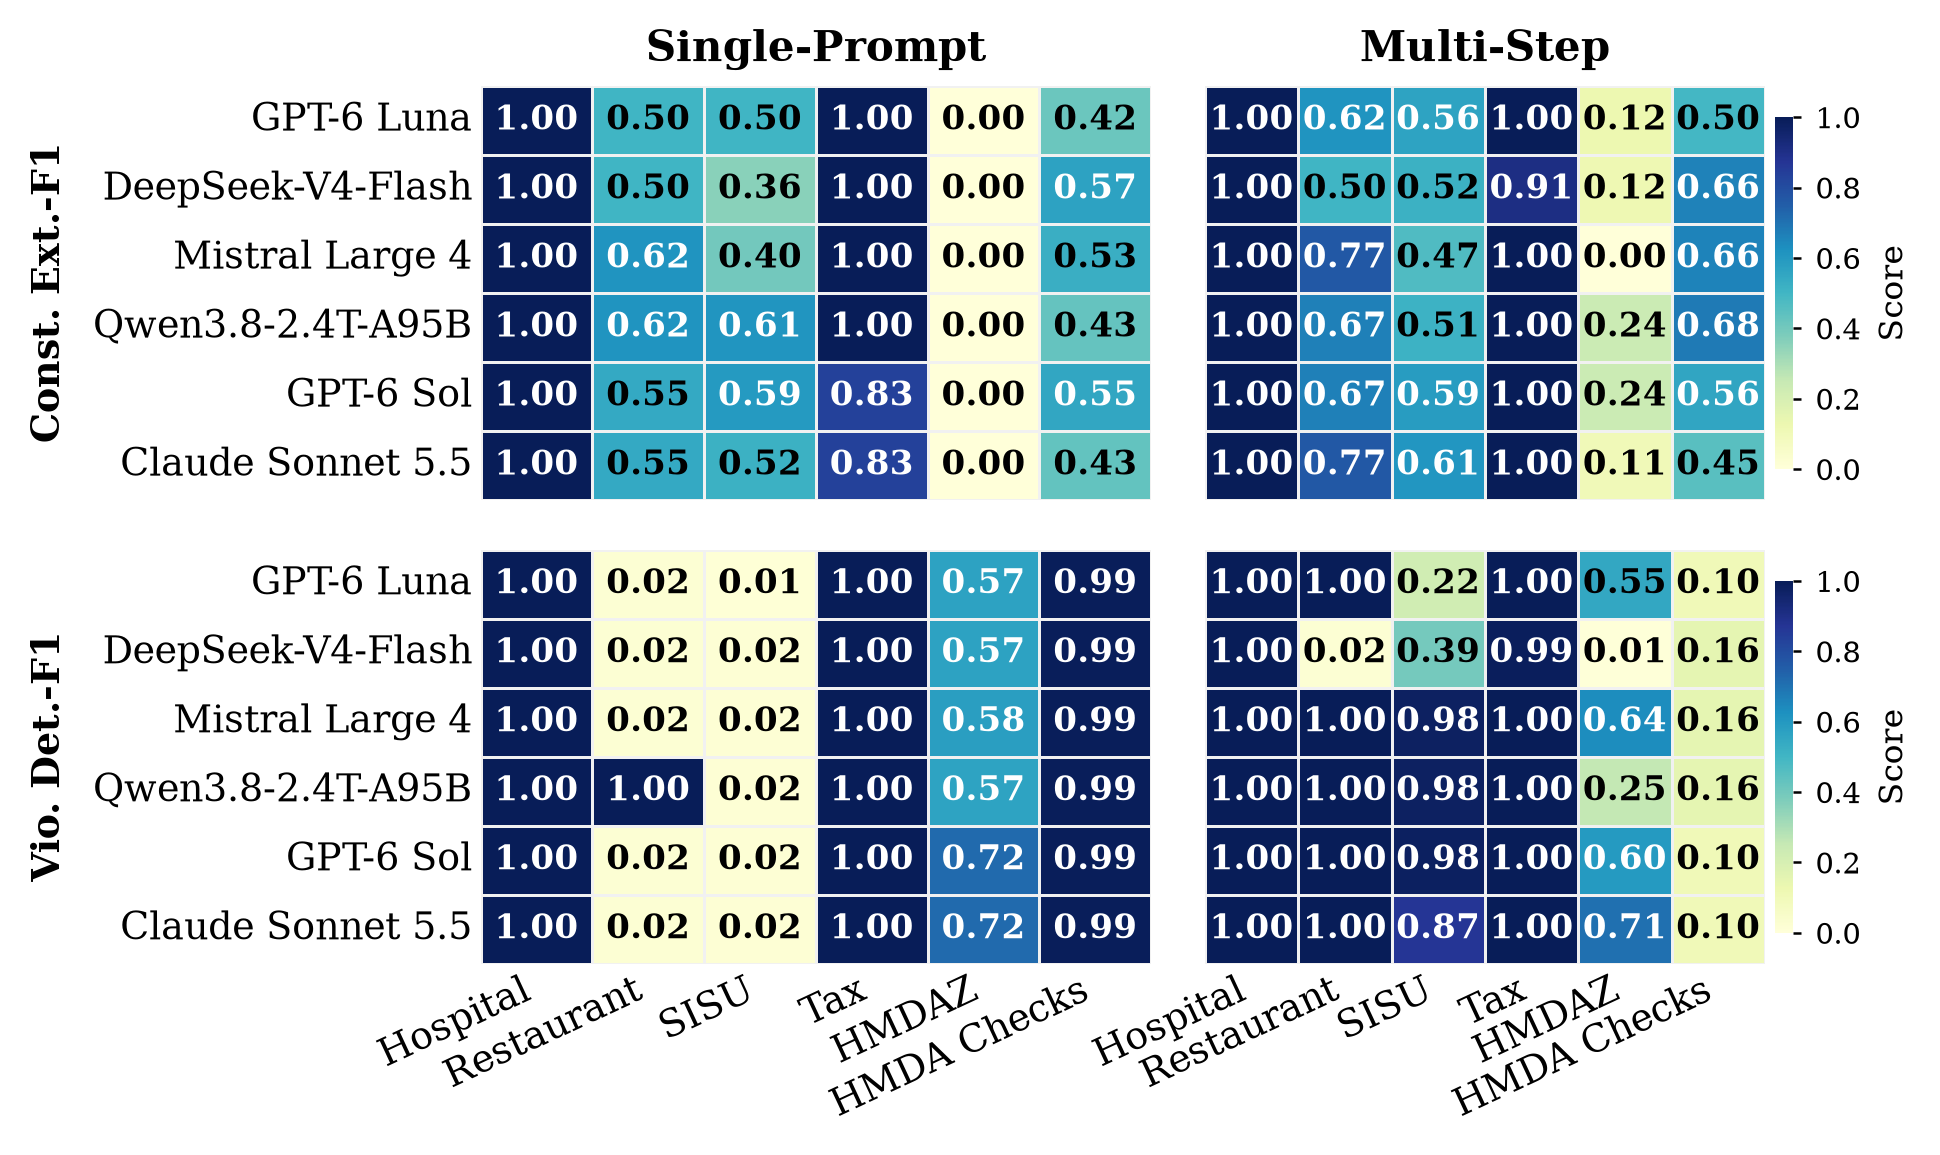

Saved heatmap (FIG_DIR, FIG_PREFIX_fig7_mapping.{pdf,png})

In [4]:
main_metrics = ["constraint_exact_f1", "agg_viol_f1"]
metric_labels = {
    "constraint_exact_f1": "Const. Ext.-F1",
    "agg_viol_f1":         "Vio. Det.-F1",
}

# Better sequential colormap for publication heatmaps
cmap = "YlGnBu"

# Ordered model / dataset display lists (depend on cell 1 variables)
ordered_models   = [model_display[m]   for m in models   if m in model_display]
ordered_datasets = [dataset_display[d] for d in datasets if d in dataset_display]

n_impl    = len(IMPLEMENTATION_ORDER)
n_metrics = len(main_metrics)

# ── Grid: rows = metrics, cols = implementations ───────────────────────────────
fig, axes = plt.subplots(
    n_metrics, n_impl,
    figsize=(3.0 * n_impl, 1.9 * n_metrics),
    gridspec_kw={"hspace": 0.12, "wspace": 0.08},
)

# Guarantee 2-D indexing
if n_metrics == 1 and n_impl == 1:
    axes = [[axes]]
elif n_metrics == 1:
    axes = [axes]
elif n_impl == 1:
    axes = [[ax] for ax in axes]

def _fmt(v):
    return f"{v:.2f}" if not pd.isna(v) else "—"

for row_idx, metric in enumerate(main_metrics):
    for col_idx, impl in enumerate(IMPLEMENTATION_ORDER):
        ax = axes[row_idx][col_idx]

        df_impl = df[df["implementation_canonical"] == impl].copy()
        df_impl["model_d"]   = df_impl["model"].map(model_display)
        df_impl["dataset_d"] = df_impl["dataset"].map(dataset_display)

        heat_data = (
            df_impl.groupby(["model_d", "dataset_d"])[metric]
            .mean()
            .unstack("dataset_d")
            .reindex(index=ordered_models, columns=ordered_datasets)
        )

        show_xticklabels = (row_idx == n_metrics - 1)
        show_yticklabels = (col_idx == 0)
        show_cbar        = (col_idx == n_impl - 1)

        hm = sns.heatmap(
            heat_data,
            ax=ax,
            annot=False,  # manual annotation below for better contrast control
            cmap=cmap,
            vmin=0.0,
            vmax=1.0,
            linewidths=0.25,
            linecolor="#f1f1f1",
            cbar=show_cbar,
            cbar_kws={"shrink": 0.85, "label": "Score", "pad": 0.015},
            xticklabels=show_xticklabels,
            yticklabels=show_yticklabels,
        )

        # Manual annotations with dynamic text color
        col_max = heat_data.max(axis=0, skipna=True)

        for i in range(heat_data.shape[0]):
            for j in range(heat_data.shape[1]):
                val = heat_data.iloc[i, j]
                label = _fmt(val)

                if pd.isna(val):
                    txt_color = "#666666"
                    fontweight = "normal"
                else:
                    txt_color = "white" if val >= 0.55 else "black"
                    fontweight = "bold" if val == col_max.iloc[j] else "semibold"

                ax.text(
                    j + 0.5, i + 0.5, label,
                    ha="center", va="center",
                    fontsize=8.2,
                    color=txt_color,
                    fontweight=fontweight,
                )

        # Implementation name as column title (top row only)
        if row_idx == 0:
            ax.set_title(
                IMPLEMENTATION_DISPLAY.get(impl, impl),
                fontweight="bold",
                pad=6
            )

        # Metric label on leftmost column only
        if show_yticklabels:
            ax.set_ylabel(metric_labels[metric], labelpad=6, fontweight="bold")
        else:
            ax.set_ylabel("")

        ax.set_xlabel("")

        # Rotate x-tick labels on bottom row only
        if show_xticklabels:
            ax.set_xticklabels(ax.get_xticklabels(), rotation=25, ha="right")

        # Keep y-tick labels horizontal on leftmost column
        if show_yticklabels:
            ax.set_yticklabels(ax.get_yticklabels(), rotation=0)

        ax.tick_params(length=0, pad=2)

        # Remove heavy subplot borders
        for spine in ax.spines.values():
            spine.set_visible(False)

        if show_cbar:
            cbar = hm.collections[0].colorbar
            cbar.ax.tick_params(labelsize=7, length=2)
            cbar.set_label("Score", size=8)

plt.savefig(FIG_DIR / f"{FIG_PREFIX}_fig7_mapping.pdf", format="pdf")
plt.savefig(FIG_DIR / f"{FIG_PREFIX}_fig7_mapping.png", format="png")
plt.show()
display(Markdown("Saved heatmap (FIG_DIR, FIG_PREFIX_fig7_mapping.{pdf,png})"))

In [5]:
metric_cols = [
    "constraint_exact_precision", "constraint_exact_recall", "constraint_exact_f1",
    "agg_viol_precision", "agg_viol_recall", "agg_viol_f1",
    "pairwise_viol_f1_mean", "pairwise_syn_exact_match",
]
table = df.assign(
    mapper=df["implementation"].map(IMPLEMENTATION_DISPLAY),
    model_label=df["model"].map(MODEL_DISPLAY),
)[["dataset", "mapper", "model_label", *metric_cols, "runtime_s"]]
table = table.sort_values(["dataset", "mapper", "model_label"])
table.to_csv(FIG_DIR / f"{FIG_PREFIX}_e2_mapping_table.csv", index=False)
display(table)

,dataset,mapper,model_label,constraint_exact_precision,constraint_exact_recall,constraint_exact_f1,agg_viol_precision,agg_viol_recall,agg_viol_f1,pairwise_viol_f1_mean,pairwise_syn_exact_match,runtime_s
10,hmda_checks,Multi-Step,Claude Sonnet 5.5,0.4800,0.4286,0.4528,1.000000,0.053800,0.102106,0.875000,0.5217,237.5685
0,hmda_checks,Multi-Step,DeepSeek-V4-Flash,0.7738,0.5804,0.6633,0.994717,0.084552,0.155856,0.711104,0.6957,2549.0229
2,hmda_checks,Multi-Step,GPT-6 Luna,0.5094,0.4821,0.4954,1.000000,0.053800,0.102106,0.833333,0.5870,293.9486
4,hmda_checks,Multi-Step,GPT-6 Sol,0.5900,0.5268,0.5566,1.000000,0.053800,0.102106,0.833333,0.6413,267.2739
6,hmda_checks,Multi-Step,Mistral Large 4,0.7805,0.5714,0.6598,0.994717,0.084552,0.155856,0.794437,0.6957,2048.6189
...,...,...,...,...,...,...,...,...,...,...,...,...
61,tax,Single-Prompt,DeepSeek-V4-Flash,1.0000,1.0000,1.0000,1.000000,1.000000,1.000000,1.000000,1.0000,19.6764
63,tax,Single-Prompt,GPT-6 Luna,1.0000,1.0000,1.0000,1.000000,1.000000,1.000000,1.000000,1.0000,13.6590
65,tax,Single-Prompt,GPT-6 Sol,0.8333,0.8333,0.8333,1.000000,1.000000,1.000000,0.944444,0.8333,9.2330
67,tax,Single-Prompt,Mistral Large 4,1.0000,1.0000,1.0000,1.000000,1.000000,1.000000,1.000000,1.0000,23.8759


In [6]:
# E2 LaTeX table (paper Table 3 style); module: notebooks/results_analysis/hmda_latex.py
from hmda_latex import e2_table

latex = e2_table(
    df.assign(model_label=df["model"].map(MODEL_DISPLAY),
              mapper=df["implementation"].map(IMPLEMENTATION_DISPLAY)),
    [IMPLEMENTATION_DISPLAY[i] for i in IMPLEMENTATION_ORDER], list(MODEL_DISPLAY.values()),
    HMDA_DATASET_ORDER, HMDA_DATASET_LABELS, GROUP_LABEL, ROW_NOTE,
)
(FIG_DIR / f"{FIG_PREFIX}_e2_mapping.tex").write_text(latex, encoding="utf-8")
print(latex)

\begin{table*}[t]
  \centering
  \small
  \setlength{\tabcolsep}{3.5pt}
  \begin{tabular}{l@{\hspace{0.6em}}rrr@{\hspace{0.6em}}rrr@{\hspace{0.6em}}rrr@{\hspace{0.6em}}rrr}
  \toprule
  & \multicolumn{6}{c}{Single-Prompt} & \multicolumn{6}{c}{Multi-Step} \\
  \cmidrule(lr){2-7} \cmidrule(lr){8-13}
  & \multicolumn{3}{c}{Const. Ext.} & \multicolumn{3}{c}{Vio. Det.} & \multicolumn{3}{c}{Const. Ext.} & \multicolumn{3}{c}{Vio. Det.} \\
  \cmidrule(lr){2-4} \cmidrule(lr){5-7} \cmidrule(lr){8-10} \cmidrule(lr){11-13}
  \textbf{Model} & P & R & F$_1$ & P & R & F$_1$ & P & R & F$_1$ & P & R & F$_1$ \\
  \midrule
  \multicolumn{13}{l}{\textit{Hospital}} \\
  ~~GPT-6 Luna & \textbf{1.00} & \textbf{1.00} & \textbf{1.00} & \textbf{1.00} & \textbf{1.00} & \textbf{1.00} & \textbf{1.00} & \textbf{1.00} & \textbf{1.00} & \textbf{1.00} & \textbf{1.00} & \textbf{1.00} \\
  ~~DeepSeek-V4-Flash & \textbf{1.00} & \textbf{1.00} & \textbf{1.00} & \textbf{1.00} & \textbf{1.00} & \textbf{1.00} & \textbf{1.00} 